In [10]:
from dotenv import load_dotenv
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper
from langchain_community.tools.tavily_search import TavilySearchResults

load_dotenv()

import os

os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["LANGCHAIN_API_KEY"] = os.getenv("LANGCHAIN_API_KEY")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"





In [11]:
api_wrapper_wiki = WikipediaAPIWrapper(
    top_k_results=1,
    doc_content_chars_max=500
)

wiki = WikipediaQueryRun(api_wrapper=api_wrapper_wiki)

tavily = TavilySearchResults()





In [12]:
### Custom Functions
def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b

# This will be a tool
def add(a: int, b: int) -> int:
    """Adds a and b.

    Args:
        a: first int
        b: second int
    """
    return a + b

def divide(a: int, b: int) -> float:
    """Divide a and b.

    Args:
        a: first int
        b: second int
    """
    return a / b



In [13]:
tools=[wiki,tavily,add,multiply,divide]

In [14]:
from langchain_groq import ChatGroq
from langchain_core.messages import AIMessage,HumanMessage,ToolMessage
from pprint import pprint
from langchain.agents import create_agent

llm_groq = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens = 200

)

llm_with_tools=llm_groq.bind_tools(tools)


In [15]:
## State Schema
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

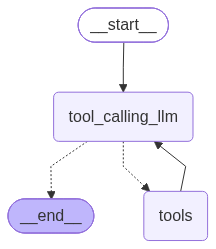

In [16]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [17]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news for MArch 3rd 2025,add 5 plus 5 and then multiply by 10")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for MArch 3rd 2025,add 5 plus 5 and then multiply by 10
================================== Ai Message ==================================

Let me fetch the top AI news for March 3rd, 2025 and perform the calculations.
Tool Calls:
  tavily_search_results_json (0d5fv7xk6)
 Call ID: 0d5fv7xk6
  Args:
    query: top AI news March 3 2025
  add (hhjg8rjr2)
 Call ID: hhjg8rjr2
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "AI round-up: Week of March 3, 2025", "url": "https://www.akhia.com/insights/benthinking/ai-round-up-week-of-march-03-2025", "content": "Story 2: AI is being tested on Super Mario Bros. (and doing pretty well) (TechCrunch)  \nBUT, can it find those secret flutes in Super Mario Bros 3?\n\nStory 3: Microsoft unveils new voice-activated assistant for doctors

In [18]:
messages=graph.invoke({"messages":HumanMessage(content="WHat is 5 plus 5")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

WHat is 5 plus 5
================================== Ai Message ==================================
Tool Calls:
  add (xvq1ae9pp)
 Call ID: xvq1ae9pp
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: add

10
================================== Ai Message ==================================

5 plus 5 equals **10**.


In [19]:
messages=graph.invoke({"messages":HumanMessage(content="Divide that by 5")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Divide that by 5
================================== Ai Message ==================================

Hello! It looks like you haven't provided a number for me to divide by 5 in this conversation yet.

Could you please specify which number you'd like me to divide by 5? Once you provide it, I'll be happy to calculate the result for you.


In [20]:
messages=graph.invoke({"messages":HumanMessage(content="What is machine learning")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is machine learning
================================== Ai Message ==================================

Machine learning is a core area of artificial intelligence (AI) that focuses on building systems that can learn from data. Instead of being explicitly programmed with rules for every possible situation, a machine learning algorithm is trained on examples (data) to find patterns and make predictions or decisions.

Here is a breakdown of the key concepts:

### 1. How It Works
*   **Data:** The system is fed large amounts of data (e.g., images, text, numbers).
*   **Training:** The algorithm processes the data to identify patterns and relationships. It adjusts internal parameters to minimize errors in its predictions.
*   **Prediction/Inference:** Once trained, the model can take new, unseen data and make predictions or decisions based on what it learned.

### 2. Main Types of Machine Learning
*   **Sup

### Lets ReWrite abvoe using Agent

In [21]:
llm_groq_agent = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens=200,
    temperature=0
)

tools_agent=[wiki,tavily,add,multiply,divide]


agent = create_agent(
    model=llm_groq_agent,
    tools=tools_agent,
    system_prompt=(
        "You are a helpful AI assistant. "
        "Use Tavily tool for news and Wikipedia for general knowledge. "
        "For calculations, always use the arithmetic tools. "
        "If the user requests multiple calculations, perform "
        "every operation in order using the appropriate tool like add and  multiply tool "
        "Your final response MUST include answers to ALL parts "
        "of the user's request, including the news and "
        "the final numerical calculation result."
    )
)

# display(
#     Image(
#         agent.get_graph().draw_mermaid_png()
#     )
# )


# ==========================================
# 9. INVOKE THE AGENT
# ==========================================

result = agent.invoke({
    "messages": [{
        "role": "user",
        "content": (
            "Add 30 + 54"
        )
    }]
})

print(result["messages"][-1].content)


result = agent.invoke({
    "messages": [{
        "role": "user",
        "content": (
            "Then add 100 in that number"
        )
    }]
})

print(result["messages"][-1].content)

# ==========================================
# 10. PRINT ALL MESSAGES
# ==========================================

# for message in result["messages"]:
#    message.pretty_print()


30 + 54 = **84**
I’d be happy to help! However, I need a bit more context:

**Which number** would you like me to add 100 to?

Could you please specify the number you're referring to? For example:
- A number from a previous conversation
- A specific value you'd like me to work with
- A number from a news article or other source

Once you let me know the number, I'll add 100 to it for you! 😊


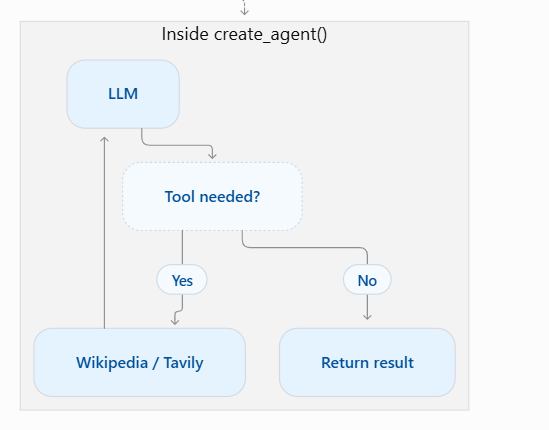

### Create agent if multiple nodes

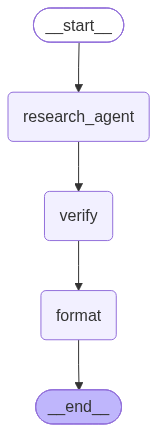


RESEARCH ANSWER:
 **Machine learning (ML)** is a field of study within artificial intelligence focused on developing and studying **statistical algorithms that can learn from data and generalize to unseen data**, enabling them to perform tasks without being explicitly programmed.

Key points:
- **Foundations:** It is built on statistics and mathematical optimization methods.
- **Core idea:** Instead of following fixed rules, ML systems identify patterns in data and use those patterns to make predictions or decisions on new, previously unseen data.
- **Related fields:** Data mining is a closely related area, particularly through *unsupervised learning*, which focuses on exploratory data analysis.

In short, machine learning is about teaching computers to improve their performance on a task through experience (data), rather than through hand-coded instructions.

VERIFIED ANSWER:
 **Machine learning (ML)** is a field of study within artificial intelligence focused on developing and study

In [22]:

from typing_extensions import TypedDict
from langchain.agents import create_agent
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage
from IPython.display import Image, display

# STEP 1: Create research agent
research_agent = create_agent(
    model=llm_groq_agent,
    tools=tools_agent,
    system_prompt=(
        "You are a research assistant. "
        "Use available tools to research questions. "
        "Do not invent facts."
    )
)

# STEP 2: Define shared state
class WorkflowState(TypedDict):
    question: str
    research_answer: str
    verified_answer: str
    final_answer: str

# STEP 3: Node 1 - Run agent
def research_node(state: WorkflowState):
    result = research_agent.invoke({
        "messages": [
            HumanMessage(content=state["question"])
        ]
    })

    return {
        "research_answer": result["messages"][-1].content
    }


def verify_node(state: WorkflowState):
    response = llm_groq_agent.invoke(
        "You are an answer reviewer.\n"
        "Review the following answer for unsupported claims "
        "and misleading certainty.\n"
        "If it is acceptable, return the ORIGINAL ANSWER unchanged.\n"
        "If it needs correction, return the CORRECTED ANSWER.\n"
        "Do not return a review, evaluation, or explanation.\n\n"
        f"Answer:\n{state['research_answer']}"
    )

    return {
        "verified_answer": response.content
    }


# STEP 5: Node 3 - Format final answer

def format_node(state: WorkflowState):
    response = llm_groq_agent.invoke(
        "Format the following answer clearly for the user. "
        "Preserve the factual content. "
        "Do not add commentary about verification.\n\n"
        f"{state['verified_answer']}"
    )

    return {
        "final_answer": response.content
    }


# STEP 6: Build parent graph
builder = StateGraph(WorkflowState)

builder.add_node("research_agent", research_node)
builder.add_node("verify", verify_node)
builder.add_node("format", format_node)

# STEP 7: Connect nodes
builder.add_edge(START, "research_agent")
builder.add_edge("research_agent", "verify")
builder.add_edge("verify", "format")
builder.add_edge("format", END)

# STEP 8: Compile graph
graph = builder.compile()

# STEP 9: Visualize
display(Image(graph.get_graph().draw_mermaid_png()))

# STEP 10: Invoke entire workflow
result = graph.invoke({
    "question": "What is machine learning?",
    "research_answer": "",
    "verified_answer": "",
    "final_answer": ""
})

print("\nRESEARCH ANSWER:\n", result["research_answer"])
print("\nVERIFIED ANSWER:\n", result["verified_answer"])
print("\nFINAL ANSWER:\n", result["final_answer"])


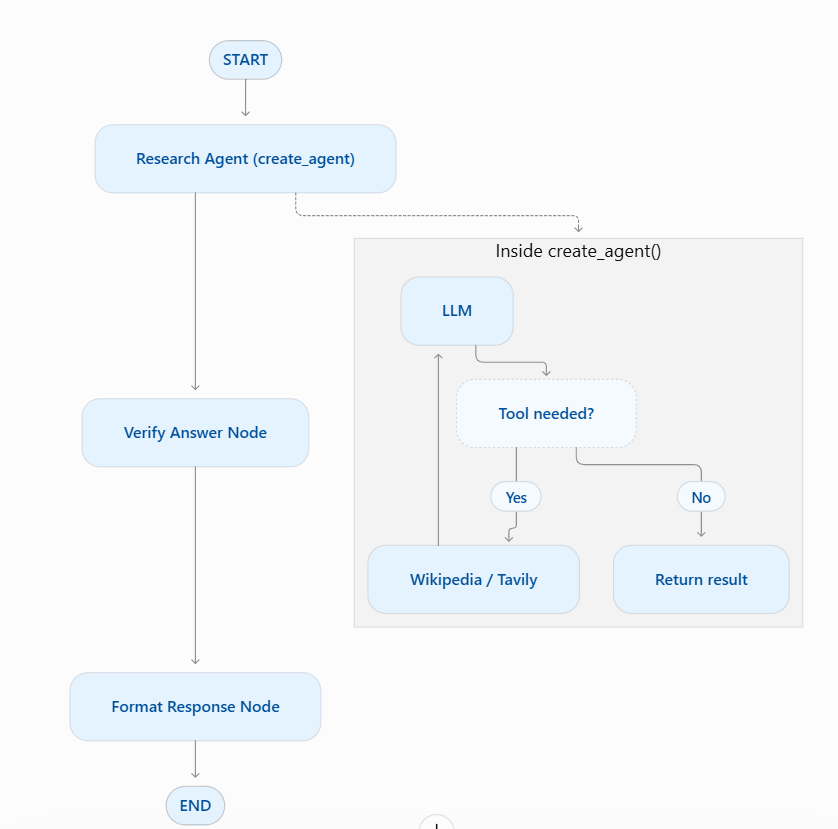

#### MemorySaver
LangGraph can use a checkpointer to automatically save the graph state after each step.

This built-in persistence layer gives us memory, allowing LangGraph to pick up from the last state update.

One of the easiest checkpointers to use is the MemorySaver, an in-memory key-value store for Graph state.

All we need to do is simply compile the graph with a checkpointer, and our graph has memory!

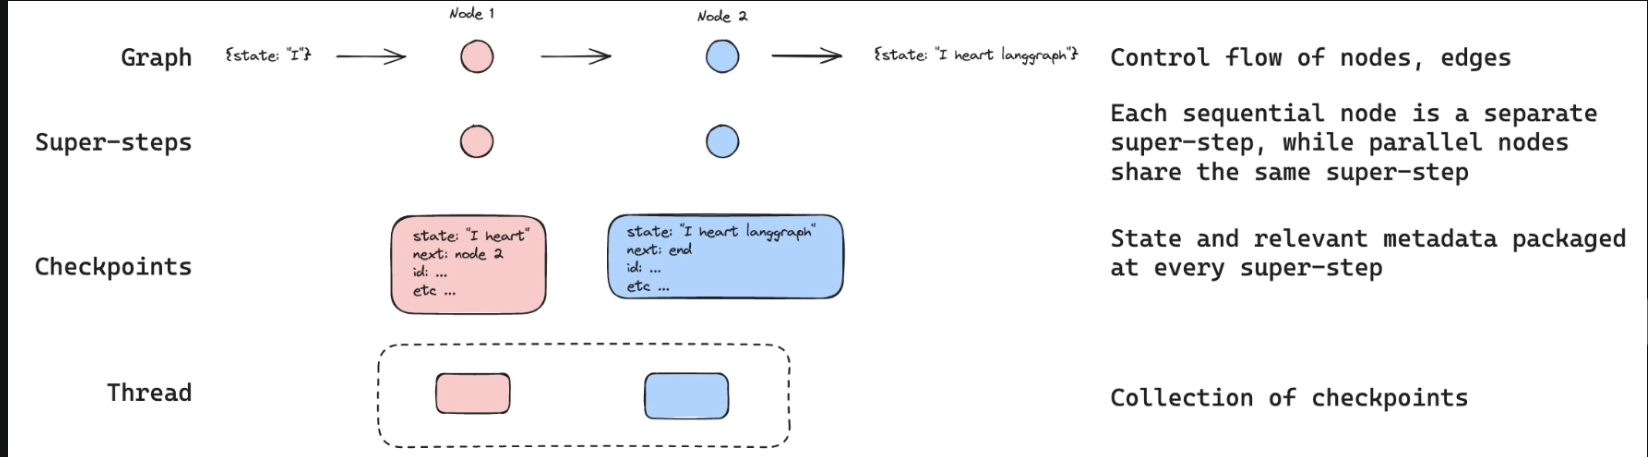

In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="WHat is 5 plus 5")})
for m in messages['messages']:
    m.pretty_print()


messages=graph.invoke({"messages":HumanMessage(content="Divide that by 5")})
for m in messages['messages']:
    m.pretty_print()

In [ ]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")





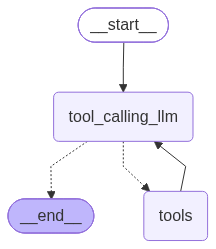

In [ ]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()
graph_memory = builder.compile(checkpointer=memory)

# View
display(Image(graph_memory.get_graph().draw_mermaid_png()))

In [ ]:
## Specify the thread

config = {"configurable":{"thread_id":"1"}}

#Specify an input

messages=graph_memory.invoke({"messages":HumanMessage(content="Add 12 and 13")}, config= config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13
================================== Ai Message ==================================
Tool Calls:
  add (f6cxa8tqb)
 Call ID: f6cxa8tqb
  Args:
    a: 12
    b: 13
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

12 + 13 = 25


In [ ]:
messages=graph_memory.invoke({"messages":HumanMessage(content="Add that number to 25")}, config= config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13
================================== Ai Message ==================================
Tool Calls:
  add (f6cxa8tqb)
 Call ID: f6cxa8tqb
  Args:
    a: 12
    b: 13
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

12 + 13 = 25
================================ Human Message =================================

Add that number to 25
================================== Ai Message ==================================
Tool Calls:
  add (q5wfxa6bh)
 Call ID: q5wfxa6bh
  Args:
    a: 25
    b: 25
================================= Tool Message =================================
Name: add

50
================================== Ai Message ==================================

25 + 25 = 50
